# Figure 3 — CDK12/13 and the PC3 transcriptional response

Reads only `data/processed/` and `data/reference/`. Nothing here recomputes a
screen statistic; if a number looks wrong the fix belongs upstream.

| panel | content | from | status |
|---|---|---|---|
| a | Lollipop, HQ461, subpool 2 | `09_analysis_and_viz/lollipop_plots_canonical.ipynb cell 15` | **figure** |
| b | CDK12/13 top hits plus HQ461-specific | `09_analysis_and_viz/logo_plots_CDK12_13_canonical.ipynb cells 19-20` | **figure** |
| c | ChimeraX renders for figure 3c (4 images), with the residues marked | `cdkbe.source_data.structures` | **figure** |
| d | CDK12/13 validation MTT | `source_data/04_MTT_data/FACS_dose_response_2024_8_22.ipynb cells 136, 142-143` | **figure** |
| f | PC3 DEG counts | `reanalysis/scripts/03_figures.py` | **figure** |
| g | PC3 drug response retained | `reanalysis/scripts/03_figures.py` | **figure** |
| h | PC3 elongation deciles | `reanalysis/scripts/06_elongation_combined.py` | **figure** |

**figure** — this notebook regenerates both the source data and the panel.
**source data** — the table regenerates and is checked by `tests/`; the
plotting is still in the original notebook named above.
**not ported** — the plotting is not in this repository yet.
See `docs/COVERAGE.md` for the status of every panel.

In [1]:
%matplotlib inline
import sys, warnings
from pathlib import Path

sys.path.insert(0, str(next(p for p in Path.cwd().resolve().parents
                            if (p / "src" / "cdkbe").is_dir()) / "src"))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from cdkbe import paths, io, editing, lfc, plotting
from cdkbe.source_data import PANELS

plotting.use_style()
paths.ensure(paths.FIG_MAIN)

## Source data

The frames these panels plot.

In [2]:
for key in ["3a", "3b", "3c", "3d", "3f", "3g", "3h"]:
    result = PANELS[key]()
    frames = result if isinstance(result, dict) else {"": result}
    for name, df in frames.items():
        label = f"{key}/{name}" if name else key
        print(f"{label:<28} {len(df):>8,} rows x {len(df.columns)} cols")

3a                              6,610 rows x 11 cols
3b                                 16 rows x 21 cols
3c                                 41 rows x 5 cols


3d                                 18 rows x 10 cols
3f                                 11 rows x 4 cols
3g/drug_response_retained          24 rows x 4 cols
3g/signature_score_per_sample       36 rows x 4 cols
3h                                110 rows x 11 cols


## Panels

Each panel below is drawn from `data/processed/` and rendered inline, and also
written to `figures/main/`. The numbers printed on the in vivo panels are
checked against the manuscript in `tests/test_invivo_figures.py`.

In [3]:
from matplotlib.figure import Figure

from cdkbe.source_data import DRAWN
from cdkbe.source_data import invivo_figures as ivf

# Drawing functions predate this notebook and return four different shapes: a
# bare figure, (figure, source rows), a dict of either keyed by gene or by
# sub-panel, or -- for the in vivo cohorts -- a list of (figure, stats) pairs.
# `show` takes them all rather than each cell knowing which it is getting.
DRAW = {k: ("invivo" if k in ivf.FIGURES else "screen", v)
        for k, v in DRAWN.items()}


def show(fig, note=None):
    if note:
        print(note)
    display(fig)
    plt.close(fig)


def describe(obj):
    if isinstance(obj, dict):
        return ", ".join(f"{e}: {len(g):,} guides" for e, g in obj.items())
    return f"{len(obj):,} rows"


def draw(key):
    """Draw one panel, show it, and report what it is made of."""
    kind, fn = DRAW[key]
    result = fn(outdir=paths.FIG_MAIN)
    if kind == "invivo":
        for fig, stats in result:
            cols = [c for c in ["Cohort", "comparison", "group",
                                "n_WT", "n_mutant", "p_shown"] if c in stats.columns]
            display(stats[cols])
            show(fig)
        return
    if isinstance(result, Figure):
        show(result)
        return
    if isinstance(result, dict):              # one figure per gene or sub-panel
        for name, v in result.items():
            if isinstance(v, Figure):
                show(v, f"{key} {name}")
            else:
                fig, sub = v
                show(fig, f"{key} {name}: {describe(sub)}")
        return
    fig, obj = result
    if not isinstance(fig, Figure):           # a ChimeraX panel: rendered images
        print(describe(obj))
        display(fig)                          # tiled preview; see structures.Renders
        return
    show(fig, describe(obj))

### 3a — Lollipop, HQ461, subpool 2

1 extra bytes in post.stringData array


'created' timestamp seems very low; regarding as unix timestamp


Zapf NOT subset; don't know how to subset; dropped


feat NOT subset; don't know how to subset; dropped


morx NOT subset; don't know how to subset; dropped


CBE: 3,366 guides, ABE: 3,244 guides


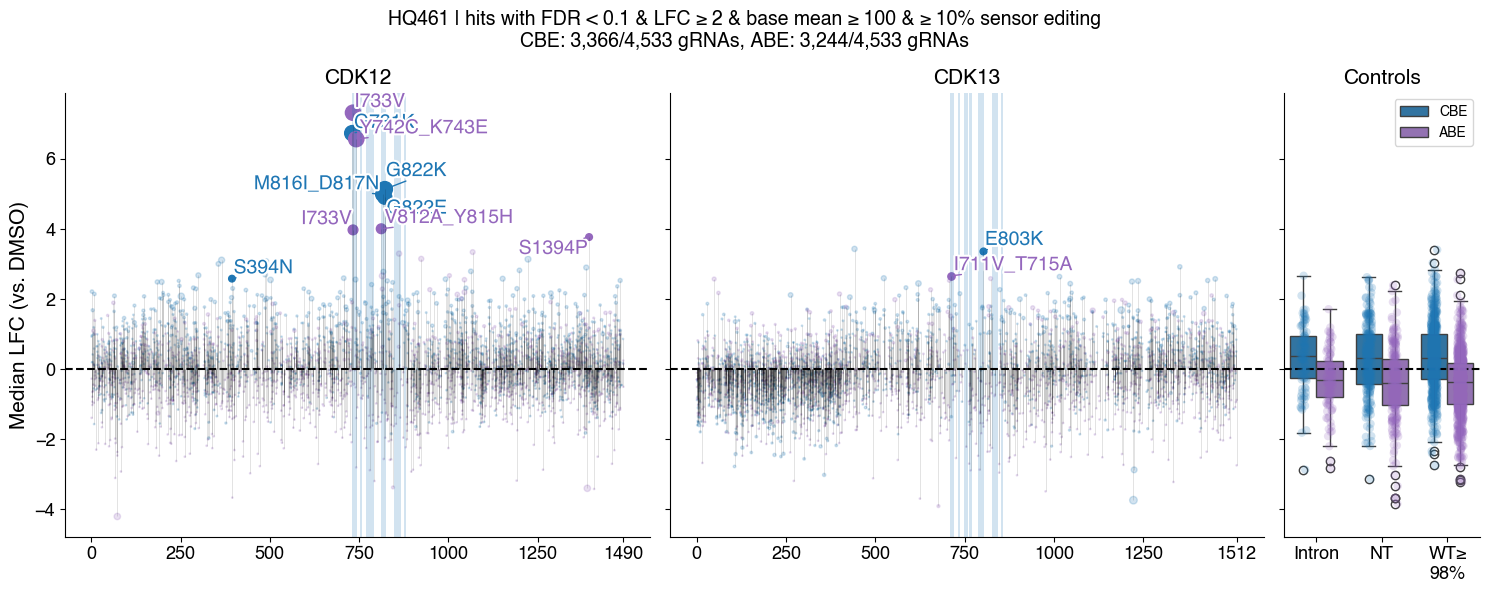

In [4]:
draw("3a")

### 3b — CDK12/13 top hits plus HQ461-specific

Matplotlib is building the font cache; this may take a moment.


1 extra bytes in post.stringData array


'created' timestamp seems very low; regarding as unix timestamp


Zapf NOT subset; don't know how to subset; dropped


feat NOT subset; don't know how to subset; dropped


morx NOT subset; don't know how to subset; dropped


16 rows


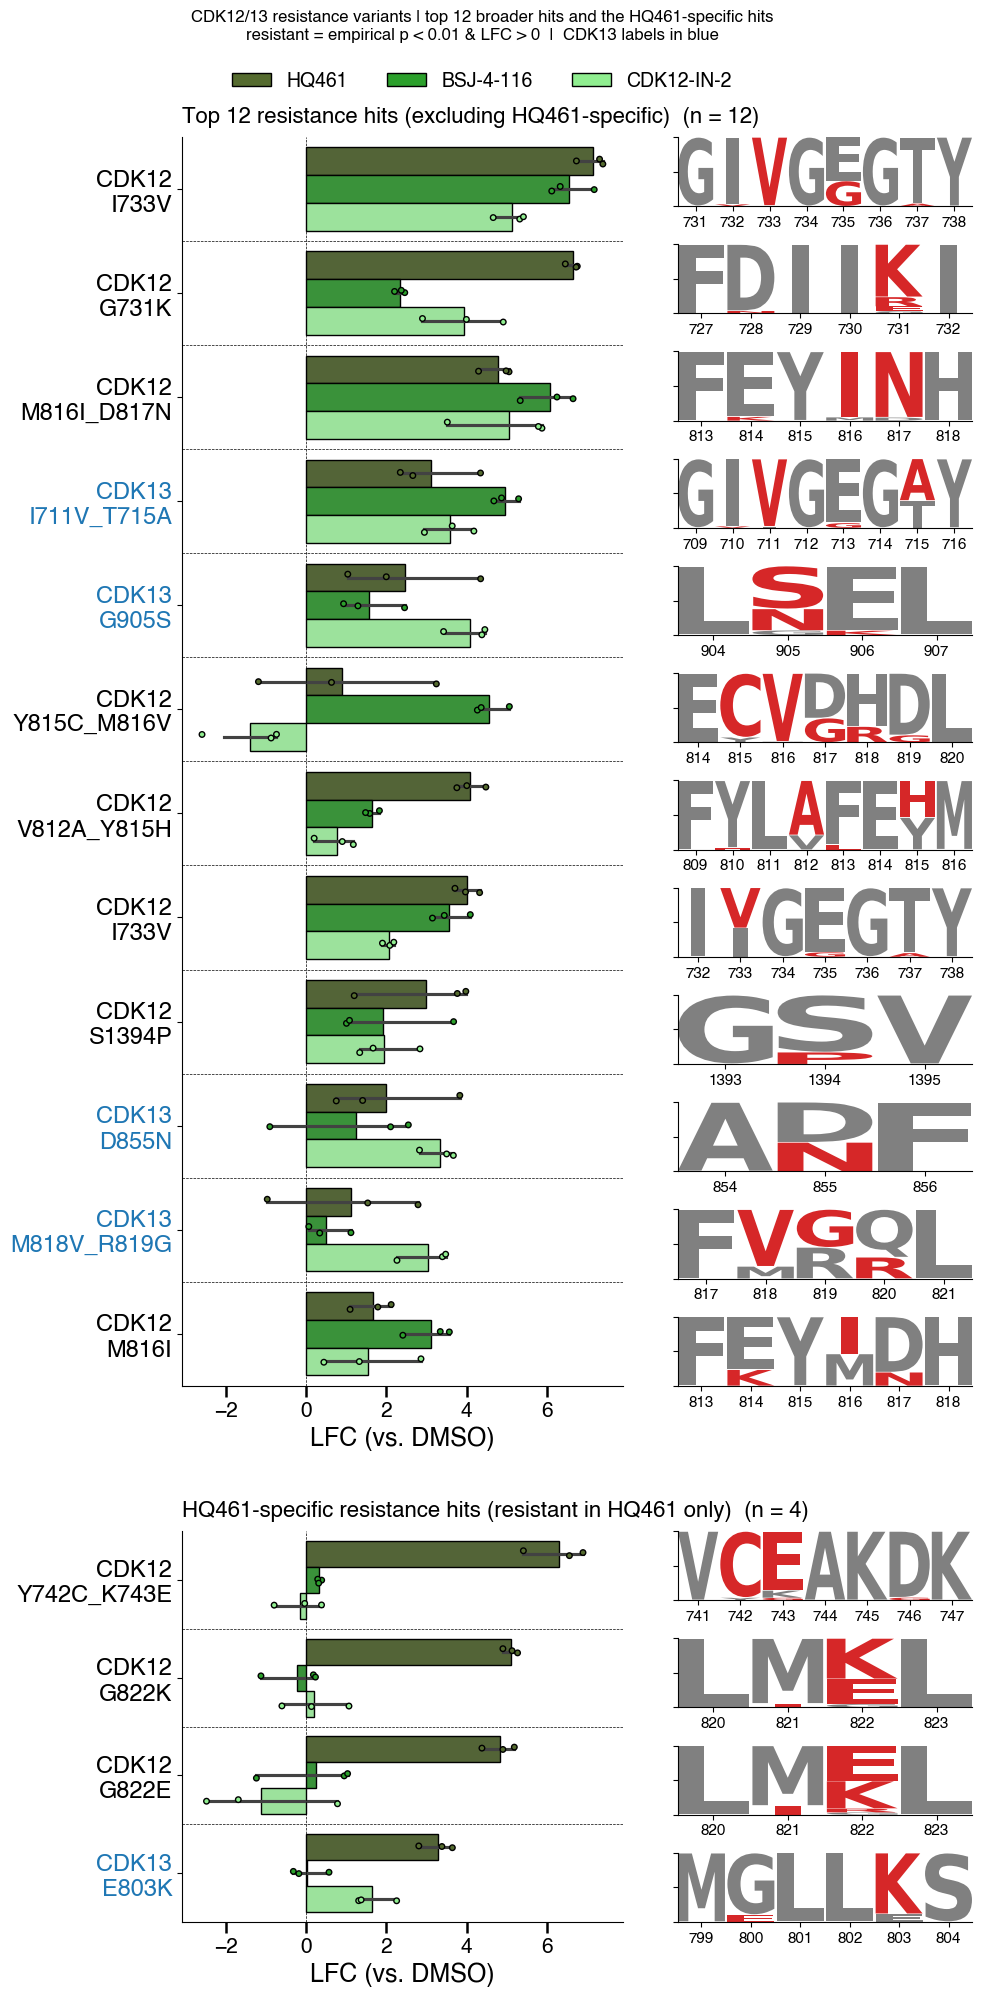

In [5]:
draw("3b")

### 3c — ChimeraX renders for figure 3c (4 images), with the residues marked

41 rows


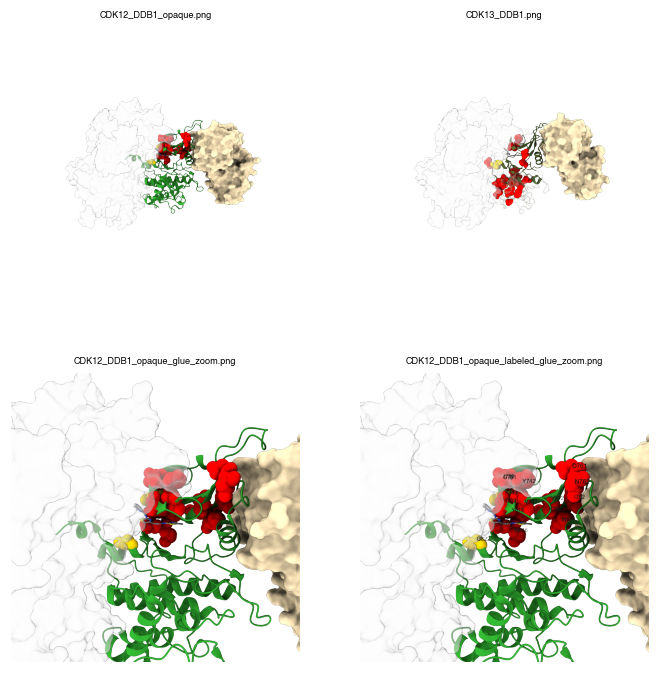

In [6]:
draw("3c")

### 3d — CDK12/13 validation MTT

1 extra bytes in post.stringData array


'created' timestamp seems very low; regarding as unix timestamp


Zapf NOT subset; don't know how to subset; dropped


feat NOT subset; don't know how to subset; dropped


morx NOT subset; don't know how to subset; dropped


18 rows


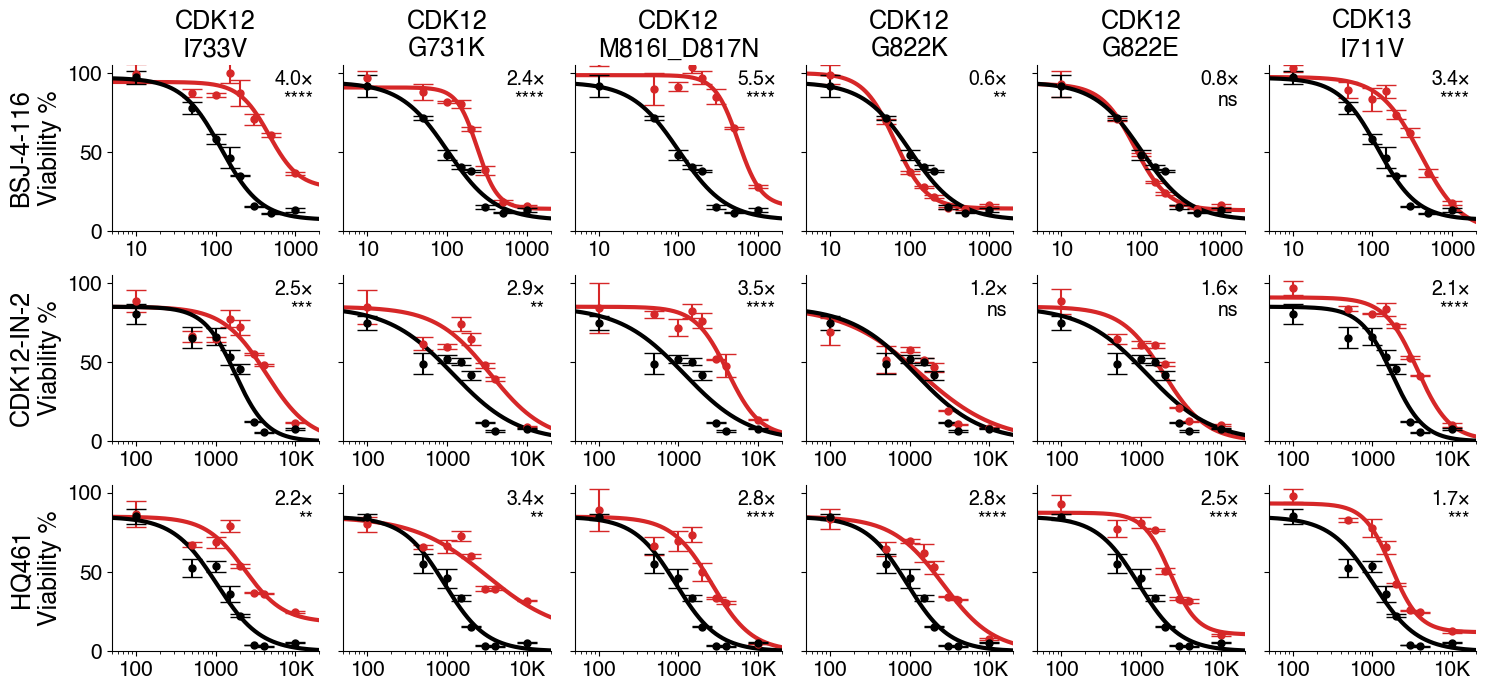

In [7]:
draw("3d")

### 3f — PC3 DEG counts

11 rows


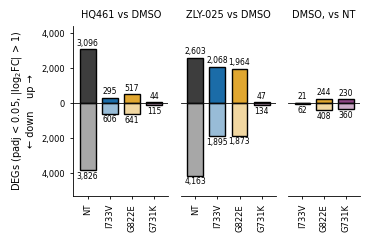

In [8]:
draw("3f")

### 3g — PC3 drug response retained

24 rows


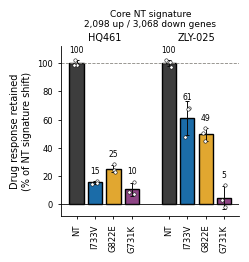

In [9]:
draw("3g")

### 3h — PC3 elongation deciles

110 rows


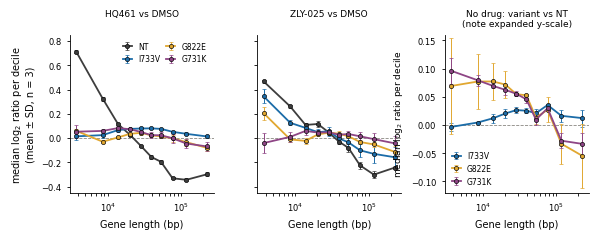

In [10]:
draw("3h")